# B4 · RoBERTa with context (workstream #5)

The same RoBERTa-base as B3, but each utterance is read together with the previous *k* turns of its dialogue and their speaker
names. This notebook shows the input, then reads the finished runs in `reports/` and `predictions/` (it trains nothing).
Write-up: `docs/B4_CONTEXT.md`. Training: `python scripts/train_b4.py` on a GPU (about 1.5 / 9 / 10 minutes per seed on an A100
for MELD / DailyDialog / EmoWOZ); tables and figures: `python scripts/analyse_b4_ctx.py --compare b4all` (CPU, seconds).

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "emotionshift").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
REPORTS = ROOT / "reports"
pd.set_option("display.width", 200)

## 1. The input: the last k turns with speaker names (code shown in the video)

In [2]:
from emotionshift.data.context import dialogue_inputs

dialogue = [("Joey", "Hey, you got the job?"), ("Rachel", "I did not."), ("Joey", "Oh. I am sorry."), ("Rachel", "It is fine, really!")]
for k in (0, 2, None):                       # 0 = B3's input, None = the whole past
    print(f"--- k = {'all' if k is None else k}: input for the last turn")
    print(dialogue_inputs(dialogue, k)[-1])

--- k = 0: input for the last turn
It is fine, really!
--- k = 2: input for the last turn
Rachel: I did not.
Joey: Oh. I am sorry.
Rachel: It is fine, really!
--- k = all: input for the last turn
Joey: Hey, you got the job?
Rachel: I did not.
Joey: Oh. I am sorry.
Rachel: It is fine, really!


## 2. Headline: k = 10 against k = all, 5 seeds (test, %)

In [3]:
from emotionshift.eval import metrics as M

rows = []
for ds in ["meld", "dailydialog", "emowoz"]:
    for tag in ["b4", "b4all"]:
        s = json.loads((REPORTS / tag / ds / "summary.json").read_text())
        split = next(iter(s["test"])); h = M.HEADLINE[ds]; t = s["test"][split]
        rows.append({"dataset": ds, "split": split, "k": s["chosen_k"], "metric": h,
                     "mean": round(100 * t[h]["mean"], 2), "sd": round(100 * t[h]["std"], 2),
                     "macro_f1": round(100 * t["macro_f1"]["mean"], 2), "seeds": len(s["seeds"])})
pd.DataFrame(rows)

,dataset,split,k,metric,mean,sd,macro_f1,seeds
0,meld,test,10,weighted_f1,63.34,0.41,40.55,5
1,meld,test,all,weighted_f1,63.30,0.42,40.57,5
2,dailydialog,test_dedup,10,micro_f1_no_neutral,58.71,0.46,45.49,5
3,dailydialog,test_dedup,all,micro_f1_no_neutral,59.62,0.82,47.42,5
4,emowoz,test,10,weighted_f1_no_neutral,84.38,0.16,60.38,5
5,emowoz,test,all,weighted_f1_no_neutral,84.31,0.22,60.10,5


## 3. Window sweep (E3): dev scores, and test by stratum

meld dev weighted_f1 -> {'1': 59.8, '3': 59.58, '5': 59.82, '10': 60.23, 'all': 60.17}
emowoz dev weighted_f1_no_neutral -> {'1': 81.88, '3': 83.01, '5': 83.47, '10': 83.55, '0': 78.98}


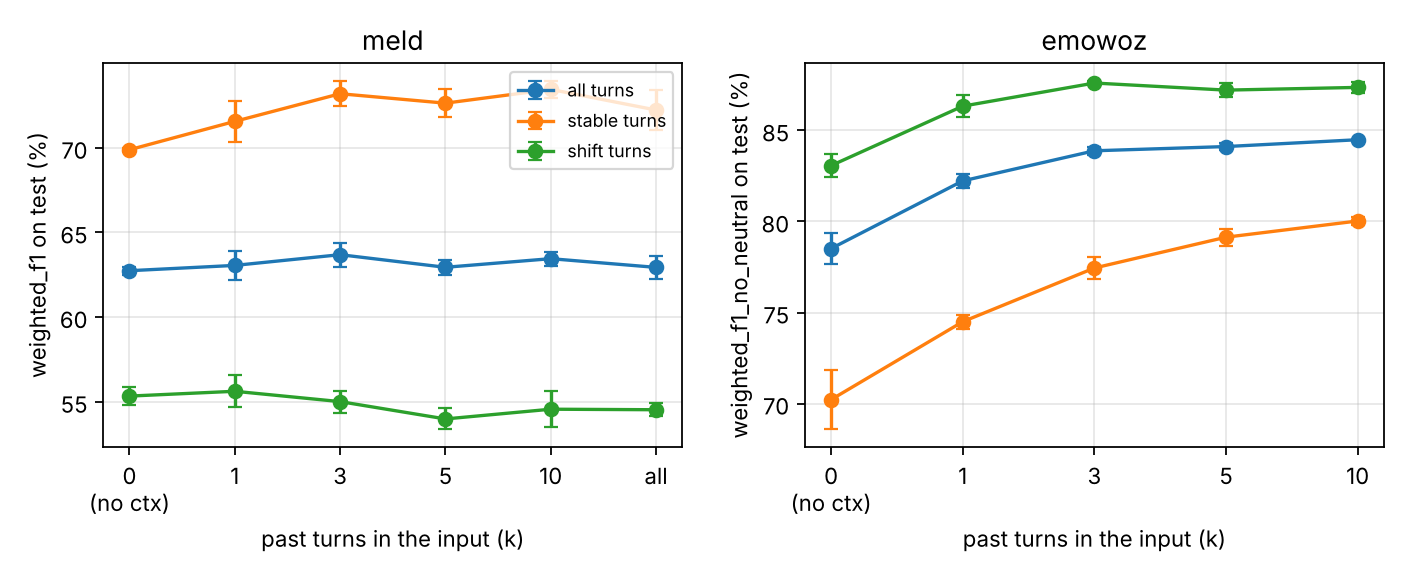

In [4]:
for ds in ["meld", "emowoz"]:
    s = json.loads((REPORTS / "b4" / ds / "summary.json").read_text())
    print(ds, "dev", s["selected_on_dev"], "->", {r["k"]: round(100 * r["dev_mean"], 2) for r in s["sweep"]})
display(Image(str(REPORTS / "b4" / "figures" / "window_sweep_test.png"), width=900))

## 4. Where the gain comes from (E2 / H1): B4 (k = 10) minus B3

meld
dailydialog
emowoz


,group,n,ref,b4,delta,ci_low,ci_high
0,all,2610,62.85,63.34,0.49,0.02,2.90
1,stratum:first,746,65.18,64.49,-0.69,-2.29,2.12
2,stratum:stable,861,69.73,72.85,3.12,1.37,5.91
3,stratum:shift,1003,55.91,54.86,-1.05,-1.50,3.15
4,shift_type:onset,355,50.25,50.35,0.10,-3.11,5.42
5,shift_type:offset,340,91.81,89.51,-2.30,-5.53,-0.92
6,shift_type:surprise,158,60.84,61.27,0.43,-0.86,10.55
7,shift_type:within_negative,81,31.78,33.47,1.70,-0.41,16.15
8,shift_type:valence_flip,69,57.77,50.45,-7.31,-16.29,6.28


,group,n,ref,b4,delta,ci_low,ci_high
0,all,7019,55.34,58.71,3.37,1.68,6.25
1,stratum:first,1782,52.67,55.83,3.16,-1.28,7.20
2,stratum:stable,4295,37.89,45.27,7.38,4.21,12.91
3,stratum:shift,942,71.46,72.19,0.73,-0.67,4.33
4,shift_type:onset,565,74.56,77.49,2.93,2.10,7.34
5,shift_type:offset,329,0.00,0.00,0.00,0.00,0.00
6,shift_type:surprise,38,59.43,60.17,0.74,-9.68,12.13


,group,n,ref,b4,delta,ci_low,ci_high
0,all,8634,78.09,84.38,6.30,4.85,8.13
1,stratum:first,1100,57.75,57.82,0.06,-8.92,8.33
2,stratum:stable,4884,69.17,80.32,11.15,7.59,15.02
3,stratum:shift,2650,82.75,87.08,4.33,3.42,5.95
4,shift_type:onset,1728,85.57,90.50,4.93,4.08,7.06
5,shift_type:offset,765,0.00,0.00,0.00,0.00,0.00
7,shift_type:valence_flip,112,82.20,80.79,-1.40,-7.08,5.24


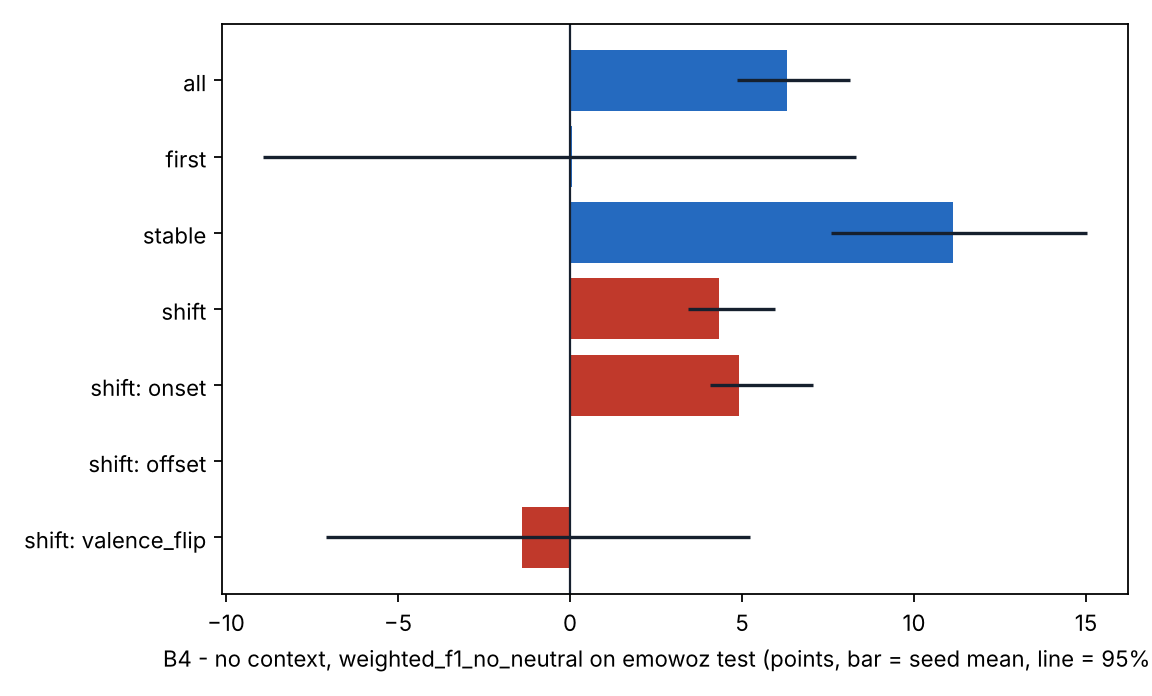

In [5]:
for ds in ["meld", "dailydialog", "emowoz"]:
    g = pd.read_csv(REPORTS / "b4" / ds / "context_gain.csv")
    g = g[g.n >= 30].assign(**{c: (100 * g[c]).round(2) for c in ["ref", "b4", "delta", "ci_low", "ci_high"]})
    print(ds); display(g)
display(Image(str(REPORTS / "b4" / "figures" / "context_gain_emowoz.png"), width=700))

## 5. Input controls (E4 / H2): the trained models with a changed input, 5 seeds

In [6]:
for tag, ds in [("b4", "meld"), ("b4", "dailydialog"), ("b4all", "emowoz")]:
    c = pd.read_csv(REPORTS / tag / ds / "controls.csv")
    t = c.pivot(index="input", columns="group", values="mean").mul(100).round(2).loc[["real", "none", "shuffled_context", "shuffled_speakers"]]
    print(tag, ds, c.metric.iloc[0]); display(t)

b4 meld weighted_f1
b4 dailydialog micro_f1_no_neutral
b4all emowoz weighted_f1_no_neutral


group,all,stratum:first,stratum:shift,stratum:stable
input,,,,
real,63.34,64.49,54.86,72.85
none,62.11,63.93,55.13,69.57
shuffled_context,61.38,63.65,53.86,69.09
shuffled_speakers,63.25,64.36,54.99,72.59


group,all,stratum:first,stratum:shift,stratum:stable
input,,,,
real,59.47,57.48,73.81,44.89
none,51.86,51.97,64.92,36.86
shuffled_context,50.06,52.08,68.07,30.95
shuffled_speakers,59.42,57.39,73.62,45.04


group,all,stratum:first,stratum:shift,stratum:stable
input,,,,
real,84.31,58.07,87.19,79.93
none,60.44,54.25,65.28,48.83
shuffled_context,70.44,58.07,77.74,53.71
shuffled_speakers,84.36,57.88,86.98,80.44


## 6. B4+ (class-weighted) for R3, and efficiency (E9)

In [7]:
b3 = json.loads((REPORTS / "b3" / "meld" / "summary.json").read_text())["test"]["test"]["macro_f1"]["mean"]
for tag in ["b4plus", "b4allplus"]:
    s = json.loads((REPORTS / tag / "meld" / "summary.json").read_text()); t = s["test"]["test"]
    print(f"B4+ k={s['chosen_k']}: macro-F1 {100 * t['macro_f1']['mean']:.2f} (B3 {100 * b3:.2f}), weighted-F1 {100 * t['weighted_f1']['mean']:.2f}")
eff = []
for ds in ["meld", "dailydialog", "emowoz"]:
    e = json.loads((REPORTS / "b4all" / ds / "summary.json").read_text())["efficiency"]
    eff.append({"dataset": ds, "parameters (M)": round(e["parameters"] / 1e6, 1), "train min / seed (A100)": round(e["train_seconds"]["mean"] / 60, 1),
                "CPU median ms": round(e["latency_one_utterance_cpu"]["median_ms"], 1), "CPU p95 ms": round(e["latency_one_utterance_cpu"]["p95_ms"], 1)})
pd.DataFrame(eff)

B4+ k=10: macro-F1 43.77 (B3 40.56), weighted-F1 58.56
B4+ k=all: macro-F1 43.59 (B3 40.56), weighted-F1 58.24


,dataset,parameters (M),train min / seed (A100),CPU median ms,CPU p95 ms
0,meld,124.7,1.6,67.8,118.7
1,dailydialog,124.7,9.1,61.3,111.7
2,emowoz,124.7,9.6,85.5,145.0


## Reading the results

- Context helps on all three datasets, mostly on **stable** turns; shift turns gain little (EmoWOZ) or nothing (MELD, DailyDialog).
- **k = 10 and k = all are within noise** on every dataset: once the window is large enough, its size does not matter.
- A shuffled history is worse than none on MELD and DailyDialog, so the model uses the right dialogue (H2).
- B4+ trades weighted-F1 for macro-F1 and beats B3 on MELD macro-F1 (R3).

Caveats are listed in `docs/B4_CONTEXT.md`.